# Coupled Map Lattice (CML)

$$u_s^{t+1} = (1-\varepsilon) f(u_s^t) + \frac{\varepsilon}{2}\big(f(u_{s+1}^t) + f(u_{s-1}^t)\big)$$

CML = **local map $f$ (혼돈)** + **확산 결합 (이웃과 같아지려는 힘)**

→ 두 부품을 따로 만들어 보고 마지막에 합친다.

1. Logistic map (칸 1개)
2. 격자 위의 확산 ($f$ 없음)
3. 합치기 = CML

---
> **표기 규칙** — 🤖 AI 표시 + `ai` 태그가 붙은 셀은 Claude가 작성. 표시 없는 셀은 직접 작성.

<sub>🤖 AI</sub>

**TODO**
- [ ] `numpy`, `matplotlib.pyplot` import

<sub>🤖 AI</sub>

In [75]:
import numpy as np, matplotlib.pyplot as plt

## 1단계: Logistic map

$$u^{t+1} = a\,u^t(1-u^t), \quad u \in [0, 1]$$

※ 위첨자 $t$는 거듭제곱이 아니라 시간 인덱스 ($u^t$ = 시각 $t$에서의 값, 코드로는 `u[t]`).

공간 없음. 숫자 하나를 계속 업데이트한다.

<sub>🤖 AI</sub>

**TODO 1-1**
- [ ] 함수 `f(u, a)` 작성
- [ ] 초기값 `u0`와 스텝 수 `T`를 받아 길이 `T+1`짜리 시계열을 돌려주는 함수 작성

<sub>🤖 AI</sub>

In [76]:
def f(u, a):
 return a * u * (1 - u)

def run(u0:float, a:float, T:int) -> np.ndarray:
    states = [u0]
    for _ in range(T):
        states.append(f(states[-1], a))
    return np.array(states)   # shape: (N_step+1, N)

**TODO 1-2**
- [ ] `a = 2.8, 3.2, 3.5, 3.9`에 대해 시계열을 subplot으로 그리기
- [ ] 각각 고정점 / 주기 2 / 주기 4 / 혼돈인지 확인

<sub>🤖 AI</sub>

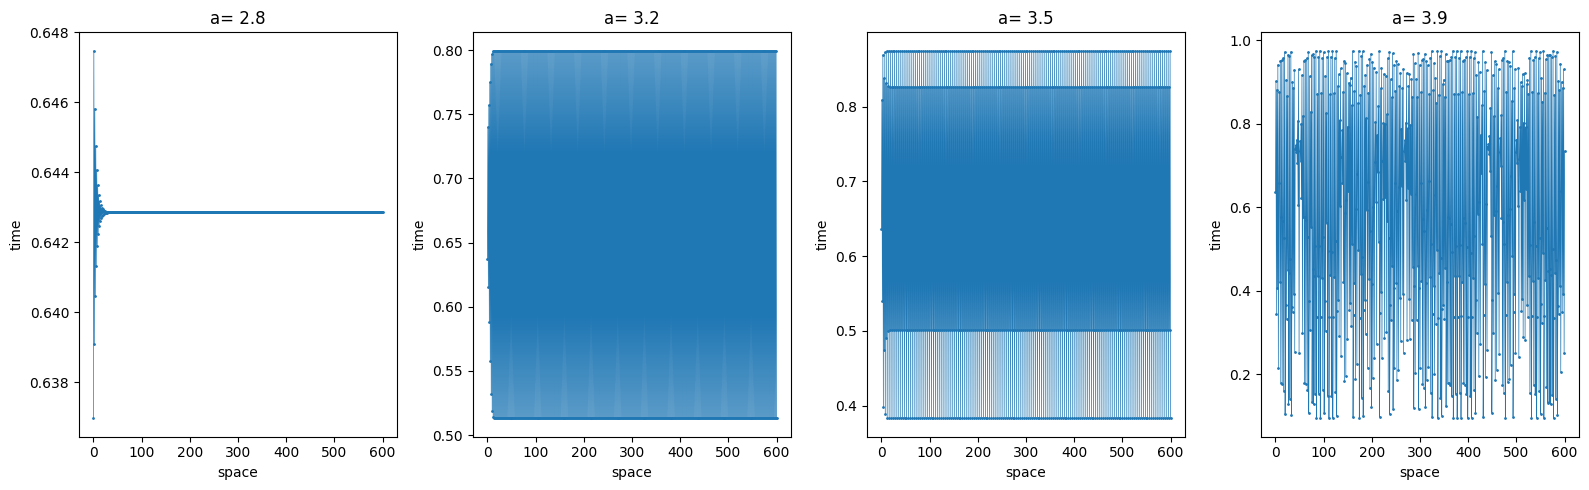

In [77]:
T = 600

CLASSES = {
    "I": 2.8,
    "II": 3.2,
    "III": 3.5,
    "IV": 3.9,
}

rng = np.random.default_rng(0)
u0 = rng.random()

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, (name, a) in zip(axes, CLASSES.items()):
    X = run(u0, a, T)
    ax.plot(X, ".-", lw=0.5, ms=2)
    ax.set_title(f"a= {a}")
    ax.set_xlabel("space")
    ax.set_ylabel("time")

plt.tight_layout()
plt.show()

**TODO 1-3 (선택)** Bifurcation diagram
- [ ] `a`를 2.5~4.0 사이에서 촘촘히 바꾸기
- [ ] 각 `a`마다 transient(예: 500 스텝)를 버리고 그 뒤 값들(예: 100개)을 점으로 찍기
- [ ] 가로축 `a`, 세로축 `u`

<sub>🤖 AI</sub>

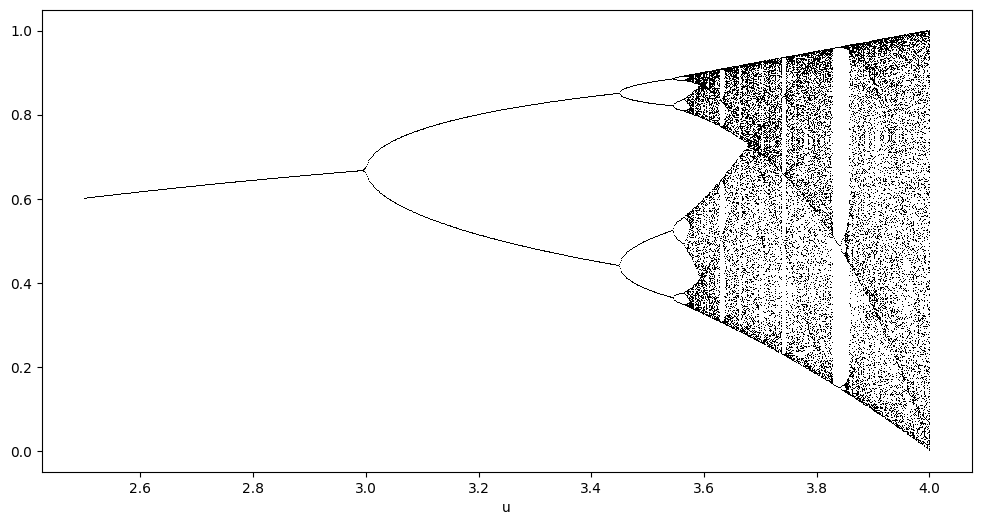

In [82]:
a_list = np.linspace(2.5, 4.0, 1000)

fig, ax = plt.subplots(figsize=(12,6))

for a in a_list:
    X = run(u0, a, 600)
    Y = X[-100:]
    ax.plot([a] * len(Y), Y, ",k")

ax.set_xlabel("a")
ax.set_xlabel("u")
plt.show()

**정리** (관찰한 것 적기)
- 


## 2단계: 격자 위의 확산

$$u_s^{t+1} = (1-\varepsilon)\,u_s^t + \frac{\varepsilon}{2}\big(u_{s+1}^t + u_{s-1}^t\big)$$

각 칸이 이웃과 값을 나눠 갖는다. 주기 경계. (CA 노트북의 `step`, `run` 구조 재활용)

<sub>🤖 AI</sub>

**TODO 2-1**
- [ ] `diffuse_step(u, eps)` 작성 (`np.roll` 사용)
- [ ] `run(step_fn, u0, T)` 작성 → shape `(T+1, N)` 배열 반환

<sub>🤖 AI</sub>

**TODO 2-2** 검증
- [ ] 출력 shape이 입력과 같은지
- [ ] 전체 합 `u.sum()`이 스텝마다 보존되는지
- [ ] 균일한 초기값 → 그대로 유지되는지

<sub>🤖 AI</sub>

**TODO 2-3** 시각화
- [ ] 초기값: 가운데 칸만 1, 나머지 0 → `imshow`로 퍼지는 모습 보기
- [ ] 초기값: 랜덤 → 매끈해지다 균일해지는 모습 보기
- [ ] `eps`를 2~3개 바꿔 비교

<sub>🤖 AI</sub>

**정리** (관찰한 것 적기)
- 


## 3단계: 합치기 = CML

2단계 식의 $u$ 자리에 $f(u)$를 넣는다.

혼돈($f$)은 칸들을 흩트리고, 확산은 칸들을 같게 만든다 → $a$, $\varepsilon$의 균형에 따라 패턴이 달라짐.

<sub>🤖 AI</sub>

**TODO 3-1**
- [ ] `cml_step(u, a, eps)` 작성
  - `f(u)`를 먼저 계산하고, 그 결과를 `np.roll`로 밀어서 이웃을 가져올 것

<sub>🤖 AI</sub>

**TODO 3-2** 검증
- [ ] `eps=0` → 각 칸이 1단계의 독립적인 logistic map과 같은지
- [ ] 균일한 초기값 → 계속 균일한지 (동기 상태)
- [ ] 값이 [0, 1] 밖으로 안 나가는지

<sub>🤖 AI</sub>

**TODO 3-3** 한 번 돌려 보기
- [ ] `rng = np.random.default_rng(0)`, 랜덤 초기값
- [ ] `N` = 100~200, transient(예: 1000 스텝) 버리고 `T` = 300~500 스텝 저장
- [ ] `imshow(X.T, ...)` (가로=시간, 세로=공간), `vmin=0, vmax=1`, colorbar

<sub>🤖 AI</sub>

**TODO 3-4** 파라미터 스캔
- [ ] `a` 몇 개 × `eps` 몇 개로 subplot 격자 만들기 (`zip(axes.flat, params)`)
- [ ] 다음 상들을 찾아보기
  - frozen pattern (세로 줄무늬처럼 굳음)
  - spatiotemporal intermittency (질서 영역 사이에 혼돈 조각이 생겼다 사라짐)
  - fully developed turbulence (전부 혼돈)
- [ ] Kaneko 논문의 상 다이어그램과 비교

<sub>🤖 AI</sub>

**TODO 3-5 (선택)** intermittency 강조
- [ ] $|u_s^t - u_s^{t-2}|$ 계산
- [ ] 임계값으로 이진화 (laminar = 0, turbulent = 1) 후 `imshow`

<sub>🤖 AI</sub>

## 정리

- [ ] 각 상을 동역학계 관점으로 정리 (Classes of CA 노트북의 fixed point / limit cycle / chaos와 연결)
- [ ] reservoir 입력용으로 `(T, N)` 배열을 `np.save`로 저장
- [ ] 커밋

<sub>🤖 AI</sub>